# Session 14: Molecular representations with RDKit

This notebook compares three ways of representing molecular structures: a custom SMARTS-based fingerprint, Morgan fingerprints, and RDKit molecular descriptors. These representations are used to predict aqueous solubility in the Delaney dataset and minimum inhibitory concentration (MIC) in the E. coli dataset using Random Forest regression.

The same functions are applied to both datasets to compare how the choice of molecular representation affects prediction performance.

In [1]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools as PT
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem import Descriptors
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from pathlib import Path
from IPython.display import HTML, display, clear_output

pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", 25)

DATA_DIR = Path.cwd() /"data"
print("Working directory:", DATA_DIR)

def display_df(**dataframes):
    html = "<div style='display: flex; gap: 16px; align-items: flex-start; overflow-x: auto;'>"
    
    for name, df in dataframes.items():
        html += f"""
        <div style='flex: 0 0 auto;'>
            <h4 style='margin-top: 0;'>{name}</h4>
            <div style='height: 250px; overflow: auto;'>
                {df.to_html()}
            </div>
        </div>
        """
    
    html += "</div>"
    display(HTML(html))

Working directory: c:\Users\mauri\OneDrive - Universität Zürich UZH\sem7\ChemicalDataScience103\assignments\session14_assignment\data


## 1. Loading and cleaning the data

The CSV files are loaded from the `data` folder relative to the working directory and stored in a dictionary using their filenames as keys. The notebook should therefore be run from the assignment folder.

For the E. coli dataset, empty or whitespace-only entries are treated as missing values, and rows without a SMILES string or MIC value are removed. The targets used later are `logS` for Delaney and `mic` for E. coli. MIC is used on its original scale without a logarithmic transformation.

In [2]:
dfs = {}

for item in DATA_DIR.iterdir():
    if item.is_file() and item.suffix.lower() == ".csv":
        dfs[item.stem] = pd.read_csv(item)
        print(f"Loaded {item.name} as dfs['{item.stem}']")

display_df(**{name: df.head(10) for name, df in dfs.items()})

Loaded delaney.csv as dfs['delaney']
Loaded ecoli_mics_sample.csv as dfs['ecoli_mics_sample']


,Compound ID,logS,smiles
0,"1,1,1,2-Tetrachloroethane",-2.18,ClCC(Cl)(Cl)Cl
1,"1,1,1-Trichloroethane",-2.00,CC(Cl)(Cl)Cl
2,"1,1,2,2-Tetrachloroethane",-1.74,ClC(Cl)C(Cl)Cl
3,"1,1,2-Trichloroethane",-1.48,ClCC(Cl)Cl
4,"1,1,2-Trichlorotrifluoroethane",-3.04,FC(F)(Cl)C(F)(Cl)Cl
5,"1,1-Dichloroethane",-1.29,CC(Cl)Cl
6,"1,1-Dichloroethylene",-1.64,ClC(=C)Cl
7,"1,1-Diethoxyethane",-0.43,CCOC(C)OCC
8,"1,2,3,4-Tetrachlorobenzene",-4.57,Clc1ccc(Cl)c(Cl)c1Cl
9,"1,2,3,4-Tetrahydronapthalene",-4.37,C1CCc2ccccc2C1


In [3]:
# Clean the E. coli dataset
df = dfs["ecoli_mics_sample"]
n_before = len(df)

df = df.replace(r"^\s*$", pd.NA, regex=True)
df = df.dropna(subset=["smiles", "mic"]).reset_index(drop=True)

dfs["ecoli_mics_sample"] = df
print(f"E. coli: removed {n_before - len(df)} rows; {len(df)} remaining.")

delaney_df = dfs["delaney"]
ecoli_df = dfs["ecoli_mics_sample"]

E. coli: removed 2 rows; 1098 remaining.


## 2. Creating and displaying molecular structures

RDKit's `PandasTools` converts the SMILES strings into molecule objects and stores them in the `images` column. These objects can be displayed as molecular structures and are also used for the subsequent fingerprint and descriptor calculations. A preview of each dataset is shown below.

In [4]:
for df in [ delaney_df, ecoli_df]:
    PT.AddMoleculeColumnToFrame(df, "smiles", "images", includeFingerprints=True)

,images
0,
1,
2,
3,
4,
5,
6,
7,
8,
9,

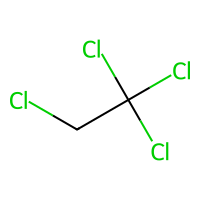
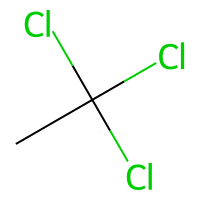
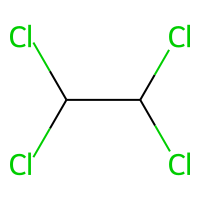
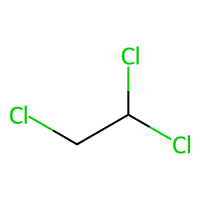
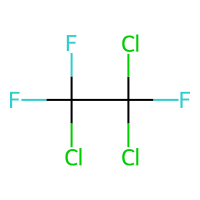
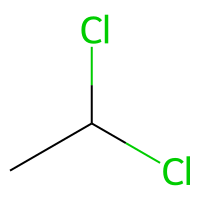
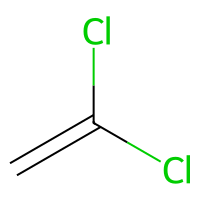
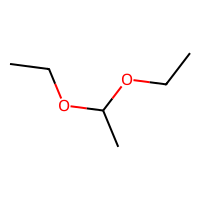
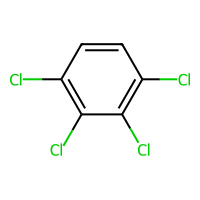
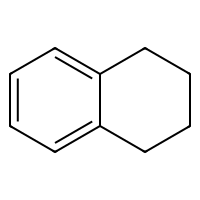
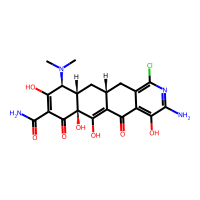
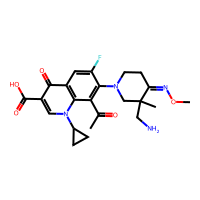
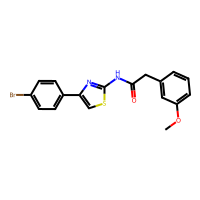
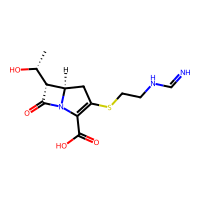
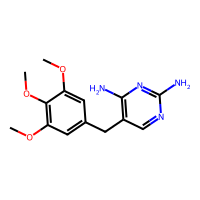
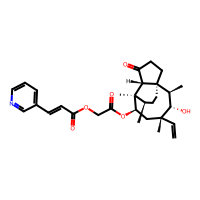
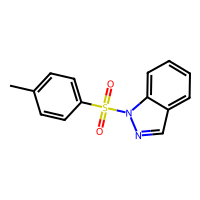
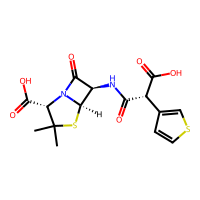
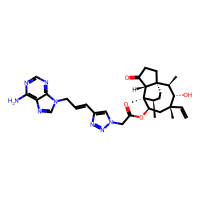
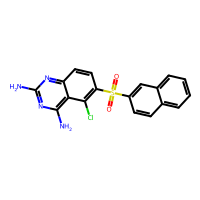

In [5]:
PT.RenderImagesInAllDataFrames(images=True)

display_df(delaney=delaney_df[["images"]].head(10), ecoli=ecoli_df[["images"]].head(10))

## 3. Custom molecular fingerprint

The custom fingerprint uses nine SMARTS patterns to check for selected molecular motifs. Each position is set to `1` if the pattern is present and `0` otherwise, in the following order:

1. Benzene ring
2. Hydroxyl group, including those in carboxylic acids
3. Ketone
4. Carboxylic acid
5. Amide
6. Amine-like nitrogen, excluding nitrogen directly attached to a carbonyl carbon
7. Halogen
8. Non-aromatic carbon–carbon double bond
9. A chain of four non-ring, non-aromatic carbon atoms

These motifs describe aspects of polarity, hydrogen bonding and the carbon skeleton that may be relevant to solubility and biological activity. They are a simple selection rather than a complete description of molecular structure. Motifs can overlap: for example, a carboxylic acid also matches the hydroxyl pattern.

The function is applied to both datasets, and the resulting lists are stored in the `fingerprint` column. The number of distinct fingerprints is counted to inspect how well this representation distinguishes molecules. Different molecules can share a fingerprint because it records only the presence of these motifs, not their number or arrangement.

In [6]:
def fingerprint(mol):
    patterns = [
        Chem.MolFromSmarts("c1ccccc1"),       # Benzene ring
        Chem.MolFromSmarts("[OX2H1]"),        # Hydroxyl (including carboxylic acids)
        Chem.MolFromSmarts("[#6][CX3](=O)[#6]"),  # Ketone
        Chem.MolFromSmarts("[CX3](=O)[OX2H1]"),   # Carboxylic acid
        Chem.MolFromSmarts("[CX3](=O)[NX3]"),     # Amide
        Chem.MolFromSmarts("[NX3;!$(N-C=O)]"),    # Amine-like N, excluding amides
        Chem.MolFromSmarts("[F,Cl,Br,I]"),    # Halogen
        Chem.MolFromSmarts("C=C"),           # Non-aromatic C=C bond
        Chem.MolFromSmarts("[CR0][CR0][CR0][CR0]"),  # Four-carbon chain outside rings
    ]

    return [
        int(mol.HasSubstructMatch(pattern))
        for pattern in patterns
    ]

,images,fingerprint
0,,"[0, 0, 0, 0, 0, 0, 1, 0, 0]"
1,,"[0, 0, 0, 0, 0, 0, 1, 0, 0]"
2,,"[0, 0, 0, 0, 0, 0, 1, 0, 0]"
3,,"[0, 0, 0, 0, 0, 0, 1, 0, 0]"
4,,"[0, 0, 0, 0, 0, 0, 1, 0, 0]"
5,,"[0, 0, 0, 0, 0, 0, 1, 0, 0]"
6,,"[0, 0, 0, 0, 0, 0, 1, 1, 0]"
7,,"[0, 0, 0, 0, 0, 0, 0, 0, 0]"
8,,"[1, 0, 0, 0, 0, 0, 1, 0, 0]"
9,,"[1, 0, 0, 0, 0, 0, 0, 0, 0]"

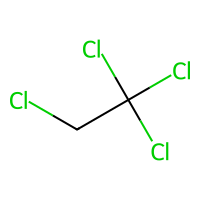
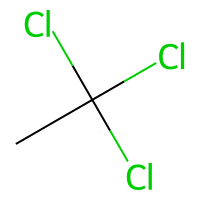
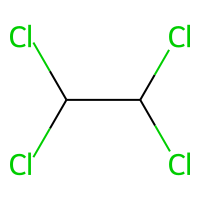
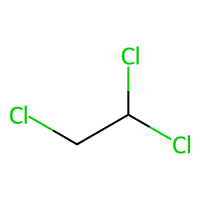
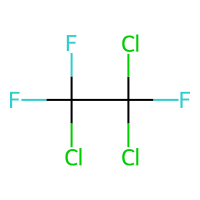
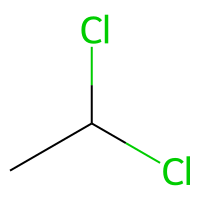
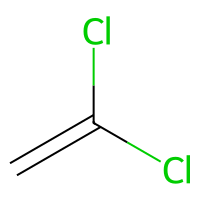
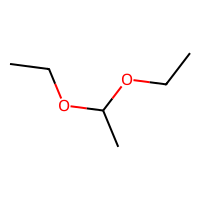
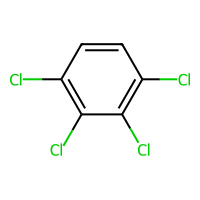
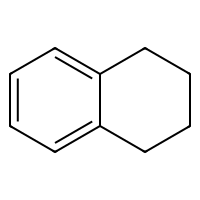
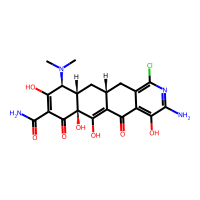
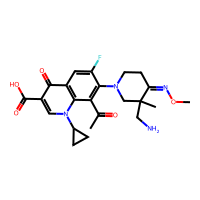
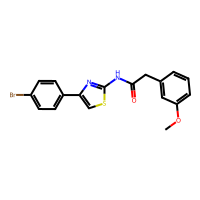
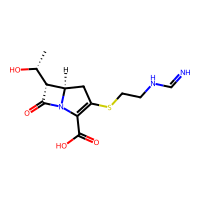
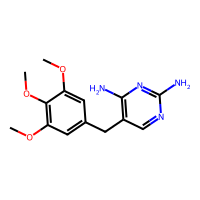
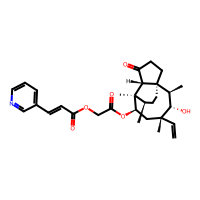
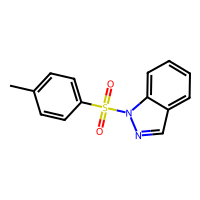
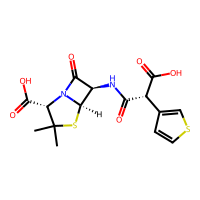
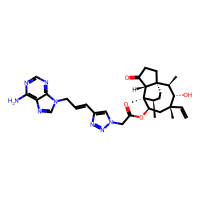
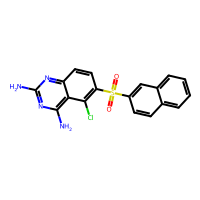

delaney: 91 distinct fingerprints across 1144 molecules
ecoli: 168 distinct fingerprints across 1098 molecules


In [7]:
delaney_df["fingerprint"] = delaney_df["images"].apply(fingerprint)
ecoli_df["fingerprint"] = ecoli_df["images"].apply(fingerprint)

display_df(delaney=delaney_df[["images", "fingerprint"]].head(10), ecoli=ecoli_df[["images", "fingerprint"]].head(10))

for name, df in {"delaney": delaney_df, "ecoli": ecoli_df}.items():
    n_unique = df["fingerprint"].apply(tuple).nunique()
    print(f"{name}: {n_unique} distinct fingerprints across {len(df)} molecules")

## 4. Morgan fingerprints

Morgan fingerprints describe local atomic environments throughout each molecule. Here, a radius of 2 includes environments extending up to two bonds from each atom, and the resulting information is encoded in a vector of 2,048 bits.

Unlike the custom fingerprint, Morgan fingerprints do not rely on a short list of manually selected motifs. They provide a more detailed structural representation, although their bits are less straightforward to interpret. Different environments can also map to the same bit.

The fingerprints are stored in a separate column, and the number of distinct vectors is counted for comparison with the custom fingerprints.

In [8]:
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,       # Explore up to two bonds from each atom
    fpSize=2048,    # Length of the binary fingerprint
)

for df in [delaney_df, ecoli_df]:
    df["morgan_fingerprint"] = df["images"].apply(
        morgan_generator.GetFingerprint
    )

In [9]:
for name, df in {"delaney": delaney_df, "ecoli": ecoli_df}.items():
    n_unique = df["morgan_fingerprint"].apply(
        lambda fp: fp.ToBitString()
    ).nunique()

    print(f"{name}: {n_unique} distinct Morgan fingerprints across {len(df)} molecules")

delaney: 1074 distinct Morgan fingerprints across 1144 molecules
ecoli: 879 distinct Morgan fingerprints across 1098 molecules


## 5. Molecular descriptors

All descriptors returned by `Descriptors.CalcMolDescriptors` are calculated for each molecule and stored in separate DataFrames. Each row corresponds to a molecule, with the original index preserved, and each column contains one descriptor.

These include molecular mass, lipophilicity, polar surface area, hydrogen-bond donor and acceptor counts, and structural and fragment descriptors. Only a selection is displayed for readability; the full set is retained for modelling.

In [10]:
def calculate_descriptors(df):
    return pd.DataFrame(
        [Descriptors.CalcMolDescriptors(mol) for mol in df["images"]],
        index=df.index,
    )

delaney_descriptors = calculate_descriptors(delaney_df)
ecoli_descriptors = calculate_descriptors(ecoli_df)

preview_columns = [
    "MolWt", "MolLogP", "TPSA",
    "NumHDonors", "NumHAcceptors",
    "NumRotatableBonds", "RingCount",
]

display_df(
    delaney=delaney_descriptors[preview_columns].head(),
    ecoli=ecoli_descriptors[preview_columns].head(),
)

,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,RingCount
0,167.850,2.5954,0.0,0,0,0,0
1,133.405,2.3765,0.0,0,0,0,0
2,167.850,2.5938,0.0,0,0,1,0
3,133.405,2.0289,0.0,0,0,1,0
4,187.375,2.9189,0.0,0,0,1,0
,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,RingCount
0,464.862,-0.24880,200.30,6,10,2,4
1,458.490,2.55380,127.22,2,7,6,4
2,403.301,4.76240,51.22,1,4,5,3
3,299.352,-0.17603,113.72,4,5,7,2


## 6. Training and evaluating the models

The reusable `compare_features` function trains a separate Random Forest regressor for each of the three feature sets. Fingerprints are converted from individual vectors stored in DataFrame cells into numerical matrices, with one row per molecule and one column per feature.

Within each dataset, the same 80/20 training/test split is used for all three models. Each forest contains 200 trees. A fixed random seed of 42 makes the split and model training reproducible.

Non-finite feature values are treated as missing. Missing values are imputed using medians learned from the training data only, so the test data do not influence this preprocessing step.

Training and test R² are reported alongside test RMSE and MAE. Higher test R² and lower test errors indicate better predictive performance. The same function is then used for both datasets.

In [11]:
def compare_features(df, descriptors, target_column):
    # Each row is a molecule; each column is a feature
    feature_sets = {
        "Custom fingerprint": np.vstack(df["fingerprint"]),
        "Morgan fingerprint": np.array(
            [list(fp) for fp in df["morgan_fingerprint"]],
            dtype=np.uint8,
        ),
        "Descriptors": descriptors.loc[df.index].to_numpy(dtype=float),
    }

    y = pd.to_numeric(df[target_column], errors="raise").to_numpy()

    # Split row positions once, then reuse for all three models
    train_idx, test_idx = train_test_split(
        np.arange(len(df)),
        test_size=0.2,
        random_state=42,
    )

    results = []

    for name, X in feature_sets.items():
        # Treat infinite descriptor values as missing
        X = np.asarray(X, dtype=float)
        X[~np.isfinite(X)] = np.nan

        model = make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1,
            ),
        )

        # Imputation learns medians from training data only
        model.fit(X[train_idx], y[train_idx])

        pred_train = model.predict(X[train_idx])
        pred_test = model.predict(X[test_idx])

        results.append({
            "Feature set": name,
            "Train R²": r2_score(y[train_idx], pred_train),
            "Test R²": r2_score(y[test_idx], pred_test),
            "Test RMSE": mean_squared_error(y[test_idx], pred_test) ** 0.5,
            "Test MAE": mean_absolute_error(y[test_idx], pred_test),
        })

    return pd.DataFrame(results).set_index("Feature set")

In [12]:
delaney_results = compare_features(
    delaney_df,
    delaney_descriptors,
    "logS",
)

ecoli_results = compare_features(
    ecoli_df,
    ecoli_descriptors,
    "mic",
)

display_df(
    delaney=delaney_results.round(3),
    ecoli=ecoli_results.round(3),
)

,Train R²,Test R²,Test RMSE,Test MAE
Feature set,,,,
Custom fingerprint,0.459,0.391,1.629,1.241
Morgan fingerprint,0.943,0.698,1.146,0.858
Descriptors,0.987,0.909,0.629,0.461
,Train R²,Test R²,Test RMSE,Test MAE
Feature set,,,,
Custom fingerprint,0.037,-0.040,3989.274,699.996
Morgan fingerprint,0.839,0.519,2714.043,546.721
Descriptors,0.850,-2.003,6778.444,1365.583


### 7. Results and discussion

#### Delaney

RDKit descriptors performed best, with a test R² of 0.909, RMSE of 0.629 and MAE of 0.461. Morgan fingerprints achieved a test R² of 0.698, while the custom fingerprint reached only 0.391.

The descriptor result is chemically plausible because properties such as lipophilicity, polar surface area and hydrogen-bonding capacity are relevant to aqueous solubility. Morgan fingerprints capture more structural detail than the nine custom motifs, but do not express these overall molecular properties directly. The custom fingerprint assigns identical representations to many different molecules, limiting its predictive ability.

Morgan fingerprints showed a larger gap between training and test R² (0.943 versus 0.698) than descriptors (0.987 versus 0.909), indicating more pronounced overfitting in this comparison.

#### E. coli

Morgan fingerprints performed best for MIC, with a test R² of 0.519, RMSE of 2714.043 and MAE of 546.721. The custom fingerprint had little predictive value, with training and test R² values of 0.037 and −0.040.

The descriptor model achieved a training R² of 0.850 but a test R² of −2.003, showing poor generalization. Its negative test R² means that its squared prediction error exceeded that of predicting the test-set mean. Morgan fingerprints also showed overfitting, but retained useful predictive performance on the test data.

For all three E. coli models, RMSE was considerably larger than MAE, indicating that large errors contributed strongly to the results. A wide MIC range or extreme observations could contribute to this pattern.

#### Comparison and conclusion

Descriptors were the best feature set for predicting solubility, whereas Morgan fingerprints were best for predicting MIC on this split. The custom fingerprint performed worst or close to worst in both datasets, suggesting that the selected motifs provide too little information for these prediction tasks.

These results show that a more detailed representation can improve predictions, but that the most useful representation depends on the target. Error magnitudes cannot be compared directly between the datasets because logS and MIC have different scales and units. These conclusions are based on a single random train/test split and may change with a different split.